# Bike-sharing demand — Phase One
## Expectation
Before running: a linear model should explain part of demand using hour, calendar and weather information. Encoding hours as categories should capture commuting peaks better than treating hour as a straight numerical slope. Temperature and feels-like temperature may be redundant. Scaling should make gradient descent stable, while a large learning rate may diverge. The required random split may be optimistic for future periods; the chronological comparison belongs to Phase Three.

Scope: Phase One only, following Sections 1.7–1.9 of the supplied project brief. All results below come from the supplied CSV files. This is an unregularized linear baseline; no polynomial expansion, feature selection, classification or final test predictions are performed.

## 1. Setup and team seed
Sort IDs as strings, join with underscores, hash with SHA-256 and take modulo 100000. Set the seed for reproducibility. Scikit-learn is used only for the mandated split, never for model fitting or prediction.

In [1]:
import hashlib
import json
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

ids = sorted(["16003585", "16003110", "14004179"])
concatenated_string = "_".join(ids)
seed = int(hashlib.sha256(concatenated_string.encode()).hexdigest(), 16) % 100000
assert int(hashlib.sha256(b"34521_40218_41190").hexdigest(), 16) % 100000 == 41698
assert seed == 29578
random.seed(seed)
np.random.seed(seed)
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11, "axes.grid": True, "grid.alpha": 0.2})
print("Python:", sys.executable)
print("Sorted IDs:", ids, "| Seed:", seed)


Python: d:\machine-learning-project-I\.venv\Scripts\python.exe
Sorted IDs: ['14004179', '16003110', '16003585'] | Seed: 29578


## 2. Load and inspect the supplied data
`cnt` is the number of hourly rentals. `instant` identifies records and is not a predictor. The hidden test file is checked for schema and submission order only; it is never split or used to tune. Missing timeline hours are reported, not filled with invented observations.

In [2]:
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data" / "train.csv").exists():
    raise FileNotFoundError("Run the notebook from the project folder containing data/train.csv")
DATA_DIR = PROJECT_DIR / "data"
train_all = pd.read_csv(DATA_DIR / "train.csv")
test_X = pd.read_csv(DATA_DIR / "test.csv")
submission_template = pd.read_csv(DATA_DIR / "sample_submission.csv")
assert "cnt" in train_all and "cnt" not in test_X
assert list(test_X.columns) == [c for c in train_all.columns if c != "cnt"]
assert submission_template["instant"].equals(test_X["instant"])
assert train_all["instant"].is_unique and test_X["instant"].is_unique
assert set(train_all.instant).isdisjoint(test_X.instant)
assert train_all.isna().sum().sum() == 0, "Inspect missing values before modeling"
assert train_all.duplicated().sum() == 0
assert (train_all.cnt >= 0).all()
display(pd.DataFrame({"file": ["train.csv", "test.csv", "sample_submission.csv"],
                      "rows": [len(train_all), len(test_X), len(submission_template)],
                      "columns": [train_all.shape[1], test_X.shape[1], submission_template.shape[1]]}))
display(train_all.head())
display(pd.DataFrame({"dtype": train_all.dtypes.astype(str), "missing": train_all.isna().sum()}))
timestamps = pd.to_datetime(train_all.dteday) + pd.to_timedelta(train_all.hr, unit="h")
assert timestamps.is_unique
full_timeline = pd.date_range(timestamps.min(), timestamps.max(), freq="h")
print("Labeled time coverage:", timestamps.min(), "to", timestamps.max())
print("Hours absent from labeled file:", len(full_timeline.difference(pd.DatetimeIndex(timestamps))))
print("Absence may include held-out test hours and operational gaps; do not assume zero demand.")


,file,rows,columns
0,train.csv,10886,15
1,test.csv,574,14
2,sample_submission.csv,574,2


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,1


,dtype,missing
instant,int64,0
dteday,str,0
season,int64,0
yr,int64,0
mnth,int64,0
hr,int64,0
holiday,int64,0
weekday,int64,0
workingday,int64,0
weathersit,int64,0


Labeled time coverage: 2011-01-01 00:00:00 to 2012-12-19 23:00:00
Hours absent from labeled file: 6370
Absence may include held-out test hours and operational gaps; do not assume zero demand.


## 3. Make the single required split
Use exactly one `train_test_split` call with `test_size=0.20` and the team seed. Keep the resulting record IDs for later phases. All fitted transformations and gradient updates use the training portion only.

In [3]:
train_df, val_df = train_test_split(train_all, test_size=0.20, random_state=seed)
train_df = train_df.copy()
val_df = val_df.copy()
assert set(train_df.instant).isdisjoint(val_df.instant)
assert len(train_df) + len(val_df) == len(train_all)
print("Training rows:", len(train_df), "| Validation rows:", len(val_df))


Training rows: 8708 | Validation rows: 2178


## 4. Prepare and scale features
Use reference-category one-hot encoding for `hr`, `season`, `weathersit`, `weekday` and `mnth`: integer codes are categories, not distances. Keep `yr`, `holiday` and `workingday` as binary predictors and the four continuous weather measurements. Derive day-of-month from `dteday`; year and month are already represented by their supplied columns. Do not add an elapsed-days trend alongside those calendar variables: it nearly duplicates their information and makes optimization poorly conditioned. Remove the raw date string and `instant`. Other calendar redundancy is retained for the later required regularization analysis.

Pool weather codes 3 and 4 into an adverse-weather category using the supplied definitions: the rare severe category cannot support its own coefficient when absent from training. This fixed domain mapping uses no target values. Learn category levels, means and population standard deviations on training rows. Drop only constant encoded columns; apply the same column order and scaling to validation. Add an unscaled intercept column. No target scaling is needed: predictions remain in rentals/hour.

In [4]:
categorical_columns = ["hr", "season", "weathersit", "weekday", "mnth"]
numeric_columns = ["yr", "holiday", "workingday", "temp", "atemp", "hum", "windspeed", "day_of_month"]
def categorical_values(frame, column):
    return frame[column].replace({4: 3}) if column == "weathersit" else frame[column]

category_levels = {c: sorted(categorical_values(train_df, c).unique().tolist()) for c in categorical_columns}

def encode_features(frame):
    dates = pd.to_datetime(frame["dteday"], errors="raise")
    numeric = frame[["yr", "holiday", "workingday", "temp", "atemp", "hum", "windspeed"]].astype(float).copy()
    numeric["day_of_month"] = dates.dt.day.astype(float)
    for column, levels in category_levels.items():
        values = categorical_values(frame, column)
        unknown = set(values.unique()) - set(levels)
        if unknown:
            raise ValueError(f"Unseen categories in {column}: {unknown}; review encoding")
        for level in levels[1:]:
            numeric[f"{column}_{level}"] = (values == level).astype(float)
    return numeric

encoded_train = encode_features(train_df)
encoded_val = encode_features(val_df)
train_std = encoded_train.std(ddof=0)
constant_columns = train_std.index[train_std == 0].tolist()
feature_names = [c for c in encoded_train if c not in constant_columns]
feature_mean = encoded_train[feature_names].mean()
feature_scale = train_std[feature_names]

def design_matrix(encoded):
    scaled = (encoded[feature_names] - feature_mean) / feature_scale
    return np.column_stack([np.ones(len(scaled)), scaled.to_numpy(dtype=float)])

X_train = design_matrix(encoded_train)
X_val = design_matrix(encoded_val)
y_train = train_df.cnt.to_numpy(dtype=float)
y_val = val_df.cnt.to_numpy(dtype=float)
weight_names = ["intercept"] + feature_names
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()
assert np.allclose(X_train[:, 1:].mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_train[:, 1:].std(axis=0), 1)
print("Design matrices:", X_train.shape, X_val.shape)
print("Dropped constant columns:", constant_columns)
display(train_df[["temp", "atemp", "yr"]].corr().round(3))


Design matrices: (8708, 54) (2178, 54)
Dropped constant columns: []


,temp,atemp,yr
temp,1.000,0.986,0.064
atemp,0.986,1.000,0.062
yr,0.064,0.062,1.000


## 5. Linear regression with gradient descent from scratch
For a design matrix with intercept, predictions are $\hat y=Xw$. Minimize $J(w)=\frac{1}{2m}\|Xw-y\|^2$ using $\nabla J=X^T(Xw-y)/m$ and update $w\leftarrow w-\alpha\nabla J$. The implementation uses full batches and zero initial weights, records training loss, and supports configurable learning rate, iteration limit, tolerance and patience. A tiny relative loss change must persist for several steps; nonfinite or explosive loss terminates a run as divergence.

Use the training Hessian $H=X^TX/m$ to calculate $L$, its largest eigenvalue. Rates below $2/L$ are stable for this quadratic objective. Compare three stable rates and one above the stability limit to demonstrate convergence behavior. Validation RMSE chooses among converged runs.

In [5]:
def gradient_descent(X, y, learning_rate, max_iter=12000, tol=1e-10, patience=20, initial_weights=None):
    if learning_rate <= 0 or max_iter < 1 or patience < 1:
        raise ValueError("Learning rate, iteration limit and patience must be positive")
    m, p = X.shape
    weights = np.zeros(p) if initial_weights is None else np.array(initial_weights, dtype=float, copy=True)
    if weights.shape != (p,):
        raise ValueError("Initial weights must match the design matrix columns")
    hessian = X.T @ X / m
    rhs = X.T @ y / m
    # Algebraically equivalent to full-batch gradients; avoids repeated row scans.
    loss = float(np.mean((X @ weights - y) ** 2) / 2)
    losses = [loss]
    initial_loss = max(loss, 1.0)
    stable_steps = 0
    status = "max_iter"
    for iteration in range(1, max_iter + 1):
        candidate = weights - learning_rate * (hessian @ weights - rhs)
        # Exact quadratic change in J, avoiding subtracting large quadratic terms.
        delta = candidate - weights
        candidate_loss = loss + float(delta @ (hessian @ weights - rhs) + 0.5 * delta @ hessian @ delta)
        if not np.isfinite(candidate_loss) or candidate_loss > initial_loss * 1e8:
            status = "diverged"
            break
        change = abs(loss - candidate_loss) / max(abs(loss), 1.0)
        weights, loss = candidate, candidate_loss
        losses.append(loss)
        stable_steps = stable_steps + 1 if change < tol else 0
        if stable_steps >= patience:
            status = "converged"
            break
    return {"weights": weights, "loss_history": np.array(losses), "iterations": len(losses)-1,
            "status": status, "learning_rate": float(learning_rate)}

def regression_metrics(y, predictions):
    errors = y - predictions
    sse = float(errors @ errors)
    sst = float(((y - y.mean()) ** 2).sum())
    return {"R2": 1 - sse / sst, "RMSE": float(np.sqrt(sse / len(y)))}

L = float(np.linalg.eigvalsh(X_train.T @ X_train / len(y_train)).max())
max_iter, tolerance, patience = 12000, 1e-10, 20
rate_factors = [0.1, 0.5, 1.0, 2.2]
runs, rows = [], []
for factor in rate_factors:
    run = gradient_descent(X_train, y_train, factor / L, max_iter, tolerance, patience)
    runs.append(run)
    scores = regression_metrics(y_val, X_val @ run["weights"]) if run["status"] != "diverged" else {"R2": np.nan, "RMSE": np.nan}
    rows.append({"rate_factor": factor, "learning_rate": run["learning_rate"], "iterations": run["iterations"],
                 "status": run["status"], "validation_R2": scores["R2"], "validation_RMSE": scores["RMSE"]})
search_results = pd.DataFrame(rows)
display(search_results.round(6))
eligible = search_results.index[search_results.status == "converged"]
assert len(eligible), "No converged run; revise training settings before continuing"
best_index = search_results.loc[eligible, "validation_RMSE"].idxmin()
best_run = runs[best_index]
phase_one_weights = best_run["weights"].copy()
print("Training-derived stable learning-rate bound:", 2 / L)
print("Selected learning rate:", best_run["learning_rate"])


,rate_factor,learning_rate,iterations,status,validation_R2,validation_RMSE
0,0.1,0.027631,9938,converged,0.697951,99.464913
1,0.5,0.138156,2506,converged,0.697949,99.465222
2,1.0,0.276312,1371,converged,0.697949,99.465300
3,2.2,0.607887,59,diverged,NaN,NaN


Training-derived stable learning-rate bound: 0.5526242245366456
Selected learning rate: 0.027631211226832285


## 6. Demonstrate convergence and check correctness
Plot training loss for every rate. Verify the analytical gradient against central finite differences on a small training subset. A least-squares solution is a numerical diagnostic only, not the model used for predictions or the Phase Two initialization. Agreement confirms that gradient descent reached the same linear optimum despite redundant columns.

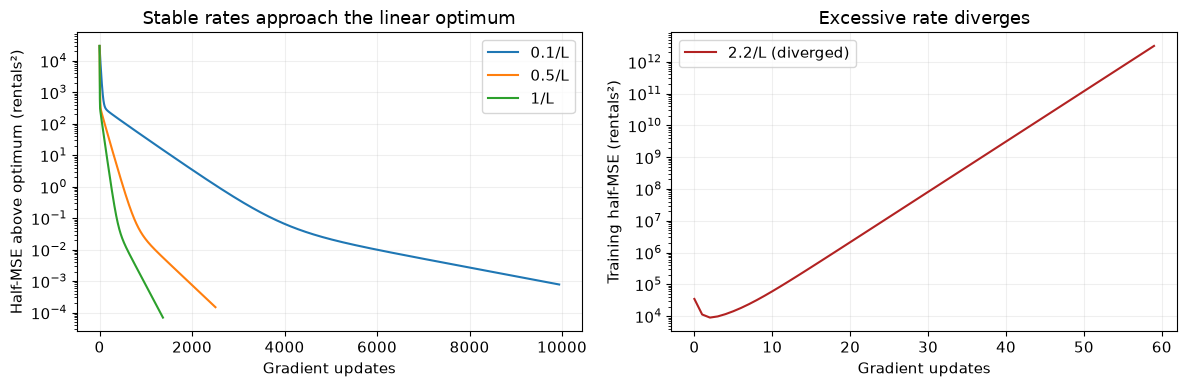

Finite-difference gradient check passed.
Training RMSE difference from least-squares optimum: 7.748022937903443e-06
Largest training prediction difference: 0.7534505581859889


In [6]:
reference_weights = np.linalg.lstsq(X_train, y_train, rcond=None)[0]
reference_loss = float(np.mean((X_train @ reference_weights - y_train)**2) / 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for run, factor in zip(runs, rate_factors):
    if run["status"] == "diverged":
        axes[1].plot(np.arange(len(run["loss_history"])), run["loss_history"], color="firebrick", label=f"{factor:g}/L (diverged)")
    else:
        excess_loss = np.maximum(run["loss_history"] - reference_loss, 1e-8)
        axes[0].plot(np.arange(len(excess_loss)), excess_loss, label=f"{factor:g}/L")
for ax in axes:
    ax.set_yscale("log")
    ax.set_xlabel("Gradient updates")
    ax.legend()
axes[0].set(ylabel="Half-MSE above optimum (rentals²)", title="Stable rates approach the linear optimum")
axes[1].set(ylabel="Training half-MSE (rentals²)", title="Excessive rate diverges")
fig.tight_layout()
plt.show()

small_X, small_y = X_train[:64], y_train[:64]
probe = np.linspace(-0.1, 0.1, X_train.shape[1])
analytic = small_X.T @ (small_X @ probe - small_y) / len(small_y)
numeric = np.zeros_like(probe)
epsilon = 1e-4
for j in range(len(probe)):
    offset = np.zeros_like(probe)
    offset[j] = epsilon
    numeric[j] = (np.mean((small_X @ (probe + offset) - small_y)**2) - np.mean((small_X @ (probe - offset) - small_y)**2)) / (4 * epsilon)
assert np.allclose(analytic, numeric, rtol=1e-5, atol=1e-4)
prediction_gap = float(np.max(np.abs(X_train @ phase_one_weights - X_train @ reference_weights)))
gd_train_rmse = regression_metrics(y_train, X_train @ phase_one_weights)["RMSE"]
reference_rmse = regression_metrics(y_train, X_train @ reference_weights)["RMSE"]
assert abs(gd_train_rmse - reference_rmse) < 0.001
assert np.all(np.diff(best_run["loss_history"]) <= 1e-7)
assert np.isclose(best_run["loss_history"][-1], gd_train_rmse**2 / 2, rtol=1e-7)
print("Finite-difference gradient check passed.")
print("Training RMSE difference from least-squares optimum:", abs(gd_train_rmse-reference_rmse))
print("Largest training prediction difference:", prediction_gap)


## 7. Evaluate the fitted baseline
Compute R² and RMSE in original rental units for training and validation. Compare against a constant predictor using the training target mean. Residuals are actual minus predicted rentals; positive residuals indicate underprediction. Do not clip negative predictions here: the reported model is the raw linear predictor. Residual structure is evidence to carry forward, not proof of a causal relationship.

,model,partition,R2,RMSE
0,gradient descent,training,0.6937,100.2631
1,training-mean baseline,training,0.0000,181.1644
2,gradient descent,validation,0.6980,99.4649
3,training-mean baseline,validation,-0.0006,181.0340


Negative validation predictions: 202


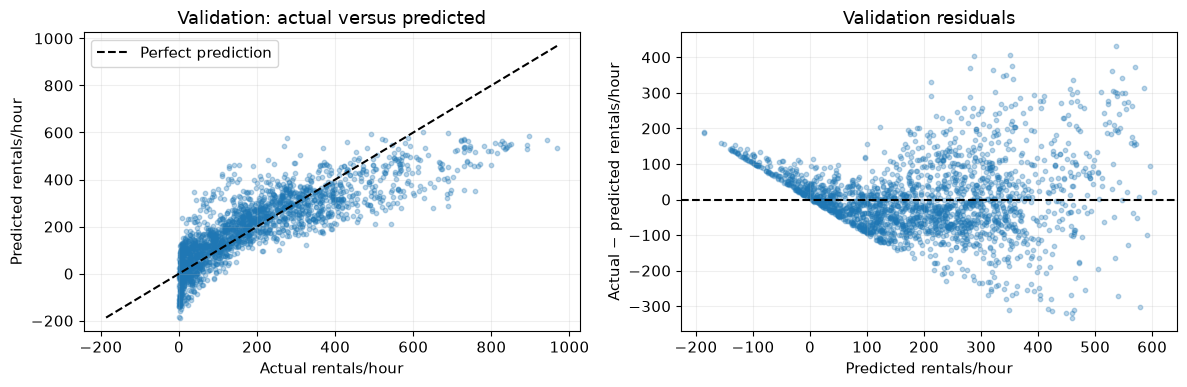

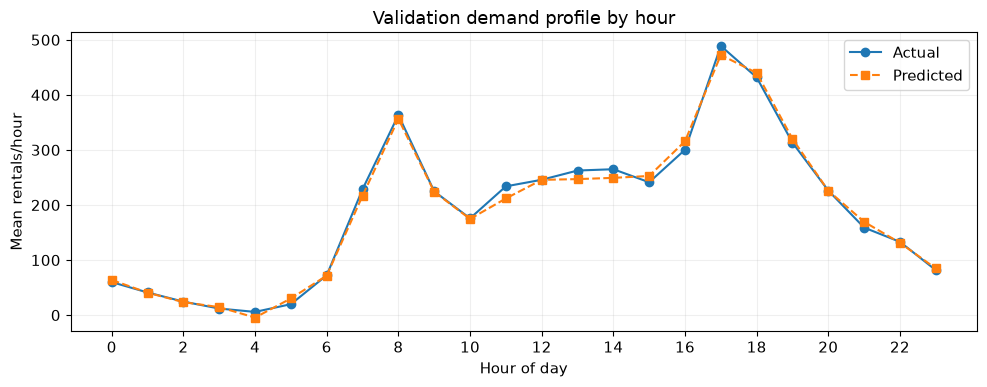

,feature,weight
0,intercept,190.69155
1,yr,43.94300
2,holiday,2.06136
3,workingday,5.33369
4,temp,15.10711
5,atemp,20.67371
6,hum,-15.64255
7,windspeed,-3.90086
8,day_of_month,1.72668
9,hr_1,-3.60831


In [7]:
train_predictions = X_train @ phase_one_weights
val_predictions = X_val @ phase_one_weights
metric_rows = []
for partition, actual, prediction in [("training", y_train, train_predictions), ("validation", y_val, val_predictions)]:
    metric_rows.append({"model": "gradient descent", "partition": partition, **regression_metrics(actual, prediction)})
    metric_rows.append({"model": "training-mean baseline", "partition": partition, **regression_metrics(actual, np.full(len(actual), y_train.mean()))})
metrics_table = pd.DataFrame(metric_rows)
display(metrics_table.round(4))
validation_metrics = regression_metrics(y_val, val_predictions)
residuals = y_val - val_predictions
print("Negative validation predictions:", int((val_predictions < 0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_val, val_predictions, s=10, alpha=0.3)
limits = [min(0, val_predictions.min()), max(y_val.max(), val_predictions.max())]
axes[0].plot(limits, limits, color="black", linestyle="--", label="Perfect prediction")
axes[0].set(xlabel="Actual rentals/hour", ylabel="Predicted rentals/hour", title="Validation: actual versus predicted")
axes[0].legend()
axes[1].scatter(val_predictions, residuals, s=10, alpha=0.3)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Predicted rentals/hour", ylabel="Actual − predicted rentals/hour", title="Validation residuals")
fig.tight_layout()
plt.show()

hourly_validation = pd.DataFrame({"hour": val_df.hr.to_numpy(), "actual": y_val, "predicted": val_predictions}).groupby("hour").mean()
fig, ax = plt.subplots()
ax.plot(hourly_validation.index, hourly_validation.actual, marker="o", label="Actual")
ax.plot(hourly_validation.index, hourly_validation.predicted, marker="s", linestyle="--", label="Predicted")
ax.set(xlabel="Hour of day", ylabel="Mean rentals/hour", title="Validation demand profile by hour", xticks=range(0,24,2))
ax.legend()
fig.tight_layout()
plt.show()
display(pd.DataFrame({"feature": weight_names, "weight": phase_one_weights}).round(5))


## 8. Preserve the Phase Two handoff
Store the final gradient-descent weights, feature order, fitted preprocessing state, split record IDs, metrics, loss history and optimization settings. Phase Two must reuse this split and initialize its existing linear coefficients from these weights, adding zeros for newly expanded features; it must not independently refit Phase One. Weight interpretation depends on standardized columns and reference-category encoding.

In [8]:
phase_one_hyperparameters = {
    "learning_rate": best_run["learning_rate"], "max_iter": max_iter,
    "iterations": best_run["iterations"], "tolerance": tolerance, "patience": patience,
    "status": best_run["status"], "initialization": "zeros", "objective": "half_mse",
}
phase_one_artifact = {
    "phase": 1, "team_ids": ids, "seed": seed,
    "weights": phase_one_weights.tolist(), "weight_names": weight_names,
    "hyperparameters": phase_one_hyperparameters,
    "preprocessing": {"date_features": ["day_of_month"], "category_levels": category_levels,
                      "weather_mapping": {"4": 3},
                      "feature_names": feature_names, "means": feature_mean.to_dict(),
                      "scales": feature_scale.to_dict(), "constant_columns": constant_columns},
    "train_record_ids": train_df.instant.tolist(), "validation_record_ids": val_df.instant.tolist(),
    "training_metrics": regression_metrics(y_train, train_predictions), "validation_metrics": validation_metrics,
    "loss_history": best_run["loss_history"].tolist(),
    "learning_rate_search": json.loads(search_results.to_json(orient="records")),
    "source_sha256": {name: hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest()
                      for name in ["train.csv", "test.csv", "sample_submission.csv"]},
}
artifact_dir = PROJECT_DIR / "artifacts"
artifact_dir.mkdir(exist_ok=True)
artifact_path = artifact_dir / "phase_one.json"
artifact_path.write_text(json.dumps(phase_one_artifact, indent=2), encoding="utf-8")
assert len(phase_one_weights) == len(weight_names)
print("Phase Two artifact saved:", artifact_path.relative_to(PROJECT_DIR))


Phase Two artifact saved: artifacts\phase_one.json


## Decisions and reasons

The assignment specifies the seed, split, from-scratch optimizer and evaluation metrics. Feature encoding, scaling, learning rates and stopping settings are engineering choices. The explanations below distinguish those choices from requirements and record the changes prompted by execution.

#### Why check the optimizer?

An optimizer is the procedure that changes coefficients to reduce training error. Here it is our `gradient_descent` function. A decreasing loss curve alone is insufficient: a wrong gradient can still decrease loss, and nearly redundant predictors can produce tiny loss changes before the optimum is reached.

Two independent checks address these risks. Central finite differences check the derivative against small changes in the objective. `np.linalg.lstsq` calculates a reference least-squares solution for the same training matrix, allowing comparison with the optimum our gradient descent should approach. It is a diagnostic, not a replacement optimizer: validation predictions and saved Phase Two weights still come from `gradient_descent`. We compare errors and predictions rather than demand identical coefficients because redundant columns can have different equivalent coefficient vectors.

The final training RMSE difference is approximately **0.00000775 rentals/hour**, below the chosen 0.001 tolerance. This establishes agreement in training objective to that tolerance; it does not establish good future performance or exact agreement for every individual prediction. The largest training prediction difference is approximately **0.75345 rentals/hour**.

#### Change 1: remove the elapsed-days feature

The initial design included elapsed days along with year, month indicators and day-of-month. The reference check failed even though the small-loss-change rule reported convergence: training RMSE was **100.26228**, versus **100.21294** for the reference optimum on that initial matrix, a gap of about **0.04934**. The smallest positive Hessian eigenvalue was approximately **3.59 × 10⁻⁷**. This identified a direction in which gradient descent improves extremely slowly.

Elapsed days is almost reconstructible from year, month and day-of-month. That near redundancy caused poor numerical conditioning. We removed elapsed days, keeping year/month plus the day-of-month extracted from the date. We chose this simpler representation rather than increasing the iteration budget dramatically or replacing gradient descent, because the calendar information remained represented and the assignment requires our optimizer. After the change, the independent optimum check passed.

**Limit:** this was a numerical-stability choice, not proof that a continuous time trend is useless. The initial and final models have different feature matrices, so their optimum scores must not be compared as if only optimization changed. Other representations could be tested later. The failed intermediate figures above document the debugging run; they are not the current model's scores or its saved handoff artifact.

#### Change 2: pool rare weather categories

The initial encoder stopped because weather code 4 occurred in validation but not in training. A separate category-4 effect cannot be estimated without training examples. Silently encoding it as all zeros would give it the clear-weather reference effect, which is a poor semantic fallback.

We mapped codes 3 and 4 to one adverse-weather group, using the brief's descriptions of light versus severe rain/snow. This mapping was chosen after observing category coverage and uses no target values or hidden-test outcomes. It is then applied identically to every partition and stored in the artifact. This is an explicit modeling assumption: severe weather is represented by the effect learned for the pooled group. It sacrifices severity detail and does not prove categories 3 and 4 have equal demand. We did not change the required seed or split to move rare examples into training.

#### Why these other choices?

| Choice | Reason and practical limit |
| --- | --- |
| One-hot hour, month, weekday, season and weather | Codes represent categories. A numeric hour slope would force the same incremental effect throughout the day; separate hour effects can capture peaks. Reference-category encoding removes the obvious full-dummy/intercept dependency, although dependencies across calendar columns remain. Cyclic encoding is an alternative, but one sine/cosine pair would impose a smooth daily shape. |
| Drop `instant` | It is a record index and can act as a proxy for ordering rather than an interpretable demand driver. This is a baseline modeling assumption, not a demonstrated verdict that it has no predictive information; column-level evidence belongs to Phase Four. |
| Training-only standardization | Different feature scales otherwise produce uneven update sizes. Training statistics prevent validation information from influencing fitted transformations. The intercept stays unscaled and rental counts retain their original units. |
| Retain `temp` and `atemp`, and other calendar redundancy | Training correlation between these weather measurements is about **0.986**, but correlation alone does not establish which predictor should be removed. Retaining them leaves that evidence-based comparison to later phases. Exact redundancy can make coefficients nonunique; prediction checks remain meaningful. |
| Full-batch updates from zero | They are deterministic and straightforward to explain for this dataset size. Linear squared-error regression is convex, so random initialization is unnecessary. Accepting an initial vector supports Phase Two's required warm start. |
| Precompute the Hessian and target cross-product | This computes the same full-batch gradient efficiently for a fixed quadratic objective. It is not a normal-equation solve or a library fit. |
| Half-MSE objective | Dividing MSE by two simplifies the gradient without changing the minimizer. Its squared-error penalty also aligns with the required RMSE evaluation. |
| Rates `0.1/L`, `0.5/L`, `1/L`, `2.2/L` | The training Hessian supplies a principled scale: stable rates lie below `2/L`. The last rate deliberately exceeds that bound to demonstrate divergence, rather than assuming every setting converges. This is a small illustrative search, not an exhaustive optimization study. |
| Select rate **0.0276312112** | It had the lowest validation RMSE among converged candidates: **99.464913**, versus **99.465222** and **99.465300**. The differences are less than 0.001 rentals/hour and do not establish a meaningful generalization advantage. We followed the stated selection rule; a speed-based tie rule could instead choose a faster converging rate. |
| Relative-loss tolerance `1e-10`, patience 20, cap 12,000 | The strict tolerance limits premature stopping; patience avoids relying on one small update, and the cap bounds runtime. These are engineering settings, not requirements or proof of convergence by themselves. The separate optimum check is important precisely because this stopping rule initially failed on the ill-conditioned design. |
| Report raw negative predictions | Clipping would change the evaluated predictor. Reporting the **202** negative validation predictions exposes a genuine operational limitation instead of hiding it. Nonnegative postprocessing may be evaluated later, but is not part of this baseline. |
| Training-mean comparison and residual plots | The constant predictor checks whether added complexity improves over a simple fit. Residual and hourly plots expose patterns an aggregate score can conceal, including underprediction of high-demand hours. They do not establish causality. |
| Separate convergence plot panels | A divergent loss reaching roughly 10¹² compressed the stable curves in the initial shared plot. Showing stable excess loss above the reference optimum separately from divergent raw loss makes both behaviors readable; labels state the different quantities. |
| Save weights, feature order, preprocessing and record IDs | Phase Two must continue this team's actual pipeline. Weights only have meaning with their feature order and transformation, and preserving IDs prevents an accidental new split. Input hashes identify the files used. |

The mandated random split and seed **29578** were not discretionary choices. We retained that split throughout debugging. Validation was used for candidate selection, so its reported score is a tuned validation estimate; unseen-period performance remains unresolved until the required chronological analysis in Phase Three.


## Outcome
The following result summary is generated from this execution rather than hard-coded. Review the plots and numbers together. The random validation estimate describes the mandated mixed-time split; it does not establish future-period performance. The operator-cost bonus is outside this baseline's scope.

In [9]:
from IPython.display import Markdown
train_metrics = regression_metrics(y_train, train_predictions)
peak_hour = int(hourly_validation.actual.idxmax())
display(Markdown(
    f"Team seed **{seed}** produced **{len(train_df):,} training / {len(val_df):,} validation rows**. "
    f"Gradient descent **{best_run['status']}** after **{best_run['iterations']:,} updates**, "
    f"using learning rate **{best_run['learning_rate']:.6f}**. "
    f"Training R² **{train_metrics['R2']:.4f}**, RMSE **{train_metrics['RMSE']:.2f}**; "
    f"validation R² **{validation_metrics['R2']:.4f}**, RMSE **{validation_metrics['RMSE']:.2f} rentals/hour**. "
    f"The observed validation mean peaks at hour **{peak_hour}**. "
    f"There are **{int((val_predictions < 0).sum())} negative validation predictions**, an operational limitation of an unconstrained linear model. "
    "An unexpected input issue was severe weather appearing only in validation; fixed pooling of weather codes 3 and 4 prevents an unlearnable category coefficient. "
    "A nearly redundant elapsed-date trend also stalled optimization and was removed in favor of the existing calendar representation. "
    "The excessive learning rate provides a divergence comparison. The actual-versus-predicted plot shows underprediction at the high-demand end. A nontrivial residual spread remains even after convergence, "
    "consistent with the expectation that an additive linear baseline cannot capture all demand structure. "
    "Calendar and weather redundancy can make individual coefficients unstable even when predictions converge; "
    "model-backed feature verdicts are deferred to Phase Four. Phase Two receives the actual fitted weights and settings."
))


Team seed **29578** produced **8,708 training / 2,178 validation rows**. Gradient descent **converged** after **9,938 updates**, using learning rate **0.027631**. Training R² **0.6937**, RMSE **100.26**; validation R² **0.6980**, RMSE **99.46 rentals/hour**. The observed validation mean peaks at hour **17**. There are **202 negative validation predictions**, an operational limitation of an unconstrained linear model. An unexpected input issue was severe weather appearing only in validation; fixed pooling of weather codes 3 and 4 prevents an unlearnable category coefficient. A nearly redundant elapsed-date trend also stalled optimization and was removed in favor of the existing calendar representation. The excessive learning rate provides a divergence comparison. The actual-versus-predicted plot shows underprediction at the high-demand end. A nontrivial residual spread remains even after convergence, consistent with the expectation that an additive linear baseline cannot capture all demand structure. Calendar and weather redundancy can make individual coefficients unstable even when predictions converge; model-backed feature verdicts are deferred to Phase Four. Phase Two receives the actual fitted weights and settings.